# Bengaluru House Price Prediction: End-to-End ML Project
**Goal:** Predict the price of houses in Bengaluru and classify them as Cheap or Expensive.
**Part A (Regression):** Linear Regression, KNN, Decision Tree, Random Forest
**Part B (Classification):** Logistic Regression, Gaussian Naive Bayes
**Metrics used:** R2, MAE, MSE, RMSE, Confusion Matrix (TP, TN, FP, FN), Accuracy, Precision, Recall, F1 Score

Imports

In [191]:
# ===== STEP 1: Libraries import karo =====
import pandas as pd  # data table handle karne ke liye
import numpy as np  # numbers ke kaam ke liye
import matplotlib.pyplot as plt  # graph banane ke liye
import seaborn as sns  # sundar graph banane ke liye
from sklearn.model_selection import train_test_split  # data ko train aur test me todne ke liye
from sklearn.preprocessing import StandardScaler  # sab columns ko ek jaisa scale karne ke liye
from sklearn.linear_model import LinearRegression, LogisticRegression  # regression model 1 aur classification model 5
from sklearn.neighbors import KNeighborsRegressor  # regression model 2
from sklearn.tree import DecisionTreeRegressor  # regression model 3
from sklearn.ensemble import RandomForestRegressor  # regression model 4
from sklearn.naive_bayes import GaussianNB  # classification model 6
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error  # regression ke error score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score  # classification ke score

Load and Understand Data

In [192]:
df = pd.read_csv("bengaluru_house_prices.csv") 

In [193]:
df.shape   # number of rows and columns

(13320, 9)

In [194]:
df.info()  # column names, types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


In [195]:
df.isnull().sum()    # missing values in each column

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [196]:
df["price"].describe()   # price ke statistics (price lakhs me hai)

count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

In [197]:
df.head()  # pehli 5 rows dikhao
# Insight: society me bahut zyada missing values hain, aur total_sqft text hai kyunki '2100 - 2850' jaisi values hain
# Cell 3: Cleaning

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


Cleaning

In [198]:
# ===== STEP 3: Data saaf karo (missing values aur duplicates) =====
df = df.drop(["society", "availability"], axis=1)  # society me 40% missing hai aur availability kaam ki nahi
df["balcony"] = df["balcony"].fillna(df["balcony"].median())  # missing balcony ko median se bhar do
df = df.dropna()  # bachi hui kuch missing rows hata do
df = df.drop_duplicates()  # duplicate rows hata do
print(df.shape)  # cleaning ke baad shape

(12555, 7)


Feature Engineering and Outliers

In [199]:
# ===== STEP 4: Kaam ke columns banao aur outliers hatao =====
df["bhk"] = df["size"].str.split(" ").str[0].astype(int)  # '2 BHK' ya '4 Bedroom' se number nikalo
df = df.drop("size", axis=1)  # ab size column ki zarurat nahi
df["total_sqft"] = pd.to_numeric(df["total_sqft"], errors="coerce")  # text ko number banao, '2100 - 2850' jaisi range NaN ban jayegi
df = df.dropna()  # un range wali rows hata do
df["location"] = df["location"].str.strip()  # location ke naam se extra space hatao
loc_cnt = df["location"].value_counts()  # har location me kitne ghar hain gino
df["location"] = np.where(df["location"].map(loc_cnt) <= 10, "other", df["location"])  # jin location me 10 ya kam ghar hain unhe 'other' bana do
df["pps"] = df["price"] * 100000 / df["total_sqft"]  # price per sqft rupees me (sirf outlier check ke liye, model ke liye nahi)
print("Before outliers:", df.shape)  # outliers hatane se pehle shape
df = df[df["total_sqft"] / df["bhk"] >= 300]  # ek bedroom ke liye kam se kam 300 sqft chahiye, warna data galat hai
df = df[df["bath"] < df["bhk"] + 2]  # bedroom se bahut zyada bathroom unrealistic hai
low = df["pps"].quantile(0.01)  # sabse kam 1% price per sqft ki value
high = df["pps"].quantile(0.99)  # sabse zyada 1% price per sqft ki value
df = df[(df["pps"] > low) & (df["pps"] < high)]  # sirf beech ka 98% data rakho
df = df.reset_index(drop=True)  # row numbers dobara 0 se shuru karo
print("After outliers:", df.shape)  # outliers hatane ke baad shape

Before outliers: (12366, 8)
After outliers: (11264, 8)


EDA Graphs (2)

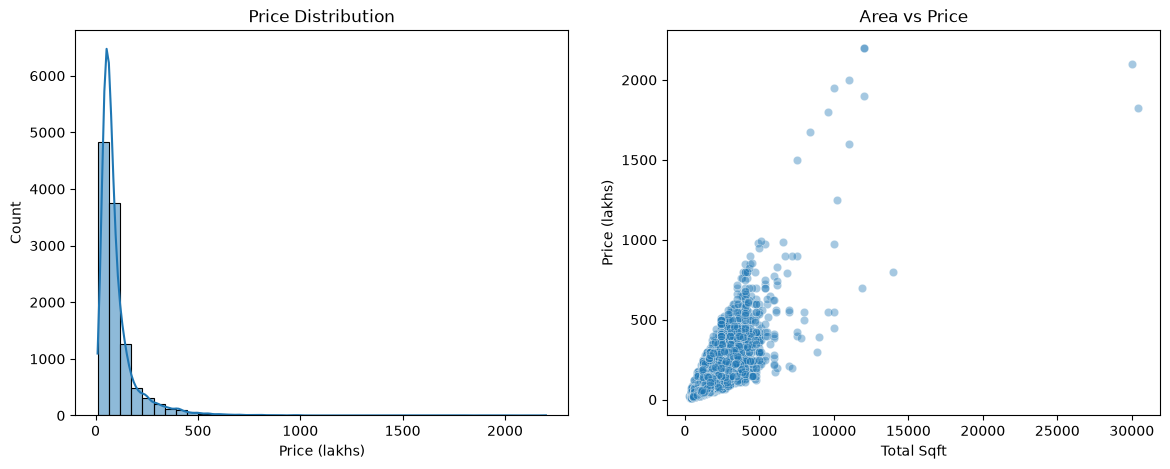

In [200]:
# ===== STEP 5: EDA graph - price distribution aur area vs price =====
plt.figure(figsize=(14, 5))  # 2 graph ke liye bada figure
plt.subplot(1, 2, 1)  # pehla graph
sns.histplot(df["price"], bins=40, kde=True)  # price kaise failaa hua hai
plt.title("Price Distribution")  # title
plt.xlabel("Price (lakhs)")  # x label
plt.subplot(1, 2, 2)  # doosra graph
sns.scatterplot(x="total_sqft", y="price", data=df, alpha=0.4)  # area vs price
plt.title("Area vs Price")  # title
plt.xlabel("Total Sqft")  # x label
plt.ylabel("Price (lakhs)")  # y label
plt.show()  # dono graph dikhao
# Insight: zyada tar ghar sasste hain aur kuch bahut mehnge (right skewed), aur bada area matlab zyada price

EDA Graphs (3)

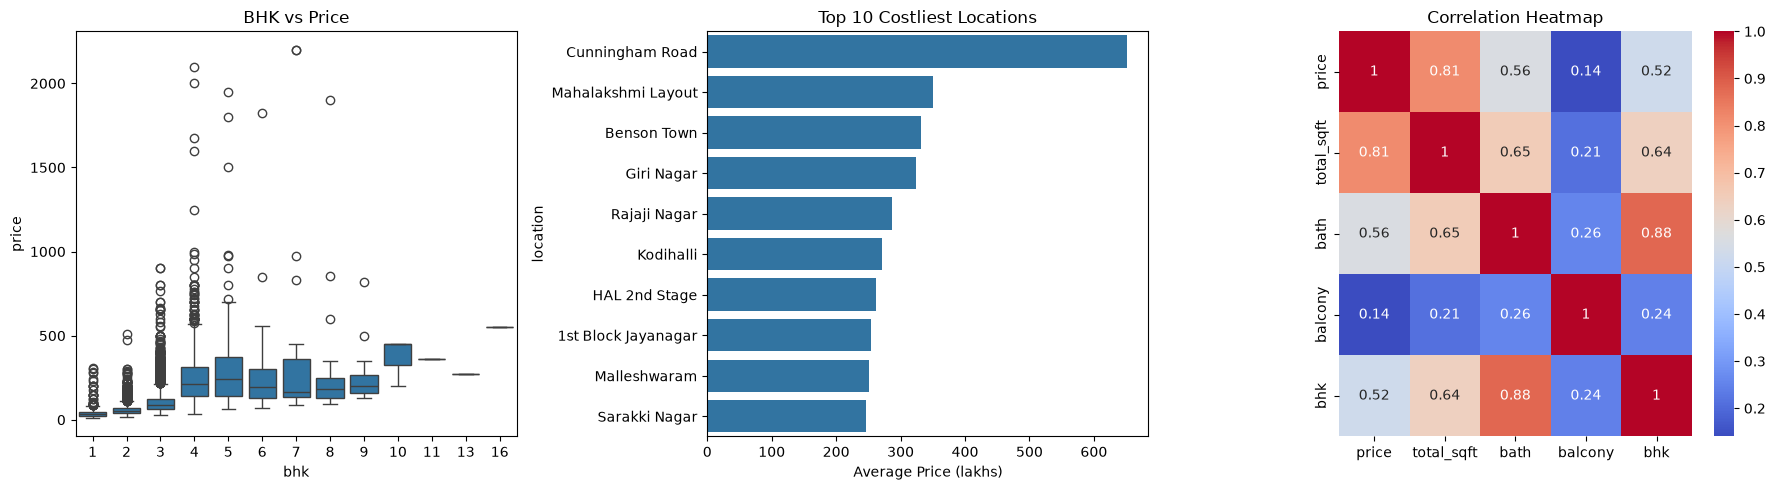

In [201]:
# ===== STEP 6: EDA graph - BHK vs price, top locations aur correlation =====
plt.figure(figsize=(18, 5))  # 3 graph ke liye bada figure
plt.subplot(1, 3, 1)  # pehla graph
sns.boxplot(x="bhk", y="price", data=df)  # har BHK ki price
plt.title("BHK vs Price")  # title
plt.subplot(1, 3, 2)  # doosra graph
top10 = df[df["location"] != "other"].groupby("location")["price"].mean().sort_values(ascending=False).head(10)  # average price ke hisab se 10 sabse mehnge location
sns.barplot(x=top10.values, y=top10.index)  # un locations ka bar graph
plt.title("Top 10 Costliest Locations")  # title
plt.xlabel("Average Price (lakhs)")  # x label
plt.subplot(1, 3, 3)  # teesra graph
sns.heatmap(df[["price", "total_sqft", "bath", "balcony", "bhk"]].corr(), annot=True, cmap="coolwarm")  # number columns ke beech correlation
plt.title("Correlation Heatmap")  # title
plt.tight_layout()  # text overlap na ho
plt.show()  # teeno graph dikhao
# Insight: BHK badhne se price badhti hai, location se price bahut badalti hai, aur total_sqft, bath, bhk price se strongly related hain

Encoding

In [202]:
# ===== STEP 7: Text columns ko number me badlo =====
df = df.drop("pps", axis=1)  # price per sqft hata do kyunki wo price se hi bana hai (data leakage)
df = pd.get_dummies(df, drop_first=True, dtype=int)  # one-hot encoding, text columns 0/1 columns ban jayenge
print(df.shape)  # ab columns kitne ho gaye

(11264, 239)


Split and Scaling

In [203]:
# ===== STEP 8: Train-test split aur scaling =====
X = df.drop("price", axis=1)  # price ke alawa sab columns
y = df["price"]  # target column
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)  # 80% train aur 20% test
print(X_tr.shape, X_te.shape)  # size check karo
sc = StandardScaler()  # scaler banao
X_tr_s = sc.fit_transform(X_tr)  # train se seekho aur scale karo
X_te_s = sc.transform(X_te)  # test ko usi rule se scale karo (data leakage nahi hoga)
# Note: scaling Linear Regression, KNN aur Logistic Regression ke liye zaroori hai, trees ko nahi chahiye par nuksan bhi nahi

(9011, 238) (2253, 238)


Train 4 Regression Models

In [204]:
# ===== STEP 9: 4 regression models train karo (Part A) =====
lr = LinearRegression()  # model 1: simple baseline, seedhi line kheenchta hai
kn = KNeighborsRegressor(n_neighbors=5)  # model 2: 5 sabse paas ke similar ghar dekhta hai
dt = DecisionTreeRegressor(max_depth=10, random_state=42)  # model 3: if-else rules, depth limit overfitting se bachane ke liye
rf = RandomForestRegressor(n_estimators=100, random_state=42)  # model 4: 100 trees ek saath

lr.fit(X_tr_s, y_tr)  # linear regression train karo
kn.fit(X_tr_s, y_tr)  # knn train karo
dt.fit(X_tr_s, y_tr)  # decision tree train karo
rf.fit(X_tr_s, y_tr)  # random forest train karo

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

Predictions

In [205]:
# ===== STEP 10: Train aur test dono pe prediction karo =====
lr_tr = lr.predict(X_tr_s)  # linear regression ka train prediction
lr_te = lr.predict(X_te_s)  # linear regression ka test prediction
kn_tr = kn.predict(X_tr_s)  # knn ka train prediction
kn_te = kn.predict(X_te_s)  # knn ka test prediction
dt_tr = dt.predict(X_tr_s)  # decision tree ka train prediction
dt_te = dt.predict(X_te_s)  # decision tree ka test prediction
rf_tr = rf.predict(X_tr_s)  # random forest ka train prediction
rf_te = rf.predict(X_te_s)  # random forest ka test prediction

p_tr = pd.DataFrame({"Linear Regression": lr_tr, "KNN": kn_tr, "Decision Tree": dt_tr, "Random Forest": rf_tr})  # sab train predictions ek table me
p_te = pd.DataFrame({"Linear Regression": lr_te, "KNN": kn_te, "Decision Tree": dt_te, "Random Forest": rf_te})  # sab test predictions ek table me

Error Metrics Table

In [206]:
# ===== STEP 11: Sab regression models ke error metrics =====
res = pd.DataFrame({  # scores ki table banao
    "Model": ["Linear Regression", "KNN", "Decision Tree", "Random Forest"],  # model ke naam
    "Train R2": [r2_score(y_tr, lr_tr), r2_score(y_tr, kn_tr), r2_score(y_tr, dt_tr), r2_score(y_tr, rf_tr)],  # train data pe R2
    "Test R2": [r2_score(y_te, lr_te), r2_score(y_te, kn_te), r2_score(y_te, dt_te), r2_score(y_te, rf_te)],  # test data pe R2 (zyada better hai)
    "Test MAE": [mean_absolute_error(y_te, lr_te), mean_absolute_error(y_te, kn_te), mean_absolute_error(y_te, dt_te), mean_absolute_error(y_te, rf_te)],  # lakhs me average error (kam better hai)
    "Test MSE": [mean_squared_error(y_te, lr_te), mean_squared_error(y_te, kn_te), mean_squared_error(y_te, dt_te), mean_squared_error(y_te, rf_te)],  # squared error (kam better hai)
})
res["Test RMSE"] = np.sqrt(res["Test MSE"])  # MSE ka square root, lakhs me
res["Gap"] = res["Train R2"] - res["Test R2"]  # bada gap matlab model overfit kar raha hai
print(res.round(3))  # table dikhao

best = res.sort_values("Test R2", ascending=False).iloc[0]["Model"]  # sabse zyada test R2 wala model
print("Best regression model:", best)  # winner print karo

               Model  Train R2  Test R2  Test MAE  Test MSE  Test RMSE    Gap
0  Linear Regression     0.739    0.743    30.056  3236.439     56.890 -0.003
1                KNN     0.777    0.570    31.202  5411.462     73.563  0.207
2      Decision Tree     0.872    0.602    30.424  5000.400     70.714  0.270
3      Random Forest     0.956    0.740    26.702  3274.816     57.226  0.216
Best regression model: Linear Regression


Model Comparison Graphs

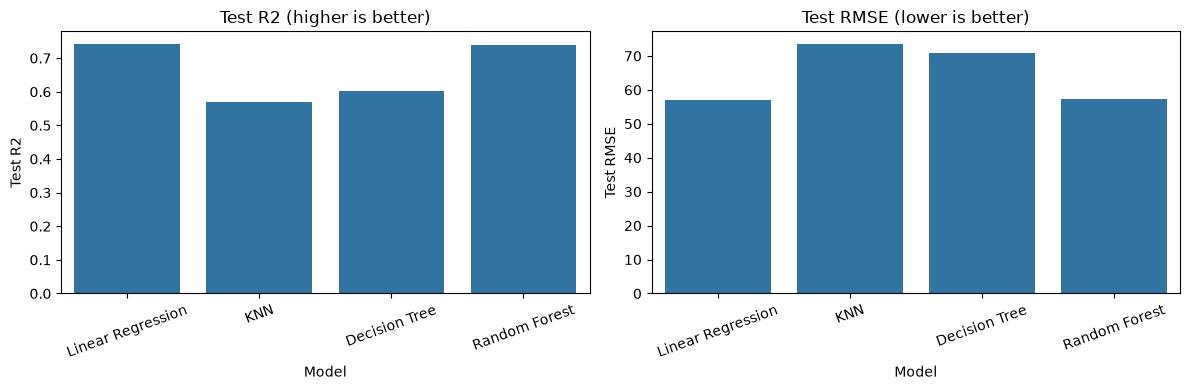

In [207]:
# ===== STEP 12: Regression models ko graph se compare karo =====
plt.figure(figsize=(12, 4))  # 2 graph ke liye figure
plt.subplot(1, 2, 1)  # pehla graph
sns.barplot(x="Model", y="Test R2", data=res)  # har model ka test R2
plt.xticks(rotation=20)  # naam thode tirche kar do
plt.title("Test R2 (higher is better)")  # title
plt.subplot(1, 2, 2)  # doosra graph
sns.barplot(x="Model", y="Test RMSE", data=res)  # har model ka test RMSE
plt.xticks(rotation=20)  # naam thode tirche kar do
plt.title("Test RMSE (lower is better)")  # title
plt.tight_layout()  # text overlap na ho
plt.show()  # dono graph dikhao

Best Model Graphs

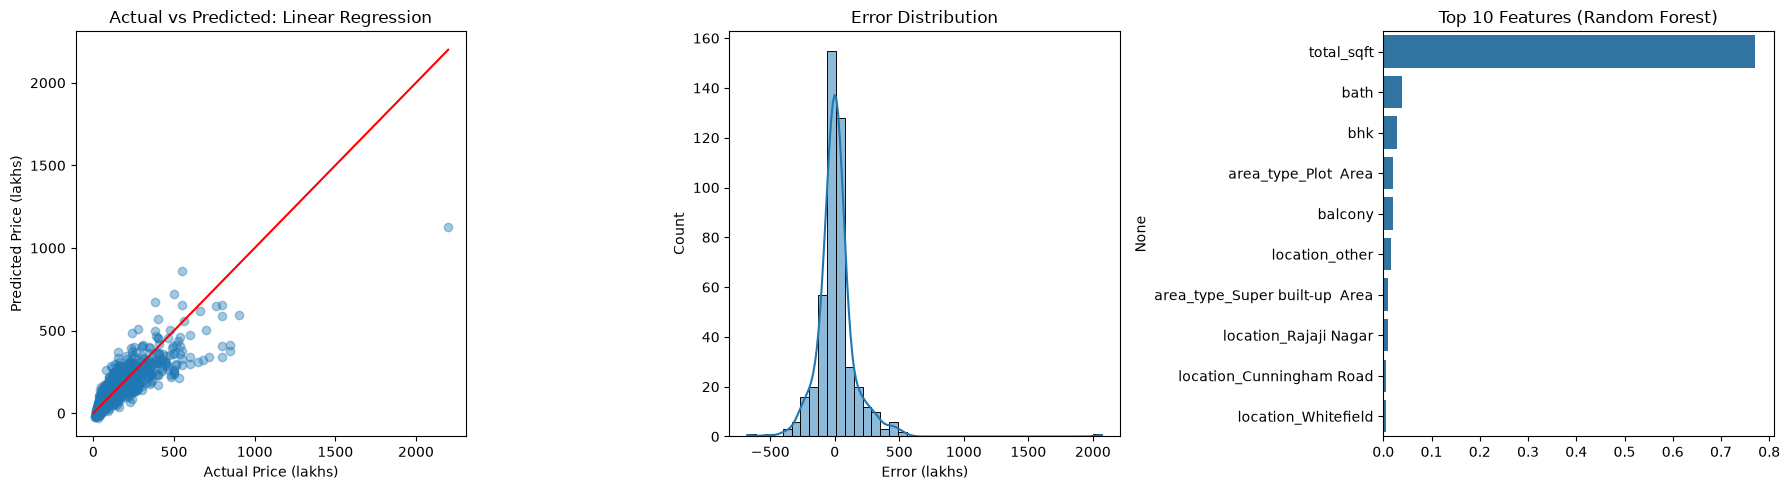

In [208]:
# ===== STEP 13: Best model ke graph - actual vs predicted, errors aur feature importance =====
best_te = p_te[best]  # best model ke test predictions
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)  # random forest se top 10 features
plt.figure(figsize=(18, 5))  # 3 graph ke liye bada figure
plt.subplot(1, 3, 1)  # pehla graph
plt.scatter(y_te, best_te, alpha=0.4)  # asli price vs predicted price
plt.plot([0, y_te.max()], [0, y_te.max()], color="red")  # laal line = perfect prediction
plt.xlabel("Actual Price (lakhs)")  # x label
plt.ylabel("Predicted Price (lakhs)")  # y label
plt.title("Actual vs Predicted: " + best)  # model ke naam ke saath title
plt.subplot(1, 3, 2)  # doosra graph
sns.histplot(y_te - best_te, bins=40, kde=True)  # errors (asli minus predicted)
plt.title("Error Distribution")  # title
plt.xlabel("Error (lakhs)")  # x label
plt.subplot(1, 3, 3)  # teesra graph
sns.barplot(x=imp.values, y=imp.index)  # feature importance ka bar graph
plt.title("Top 10 Features (Random Forest)")  # title
plt.tight_layout()  # text overlap na ho
plt.show()  # teeno graph dikhao
# Insight: laal line ke paas points matlab achhi prediction, bahut mehnge gharon me error zyada hai, total_sqft sabse zyada matter karta hai

Cheap/Expensive Classes + Logistic + Naive Bayes

In [209]:
# ===== STEP 14: Part B - Cheap/Expensive class banao aur classification models train karo =====
# Price ek number hai, isliye 2 class banate hain: training median se upar = Expensive (1), warna Cheap (0)
cut = y_tr.median()  # training price ka median hi dividing line hai
a_tr = (y_tr > cut).astype(int)  # train data ki asli class
a_te = (y_te > cut).astype(int)  # test data ki asli class
b_tr = (p_tr[best] > cut).astype(int)  # best regression model ka train prediction class me badla
b_te = (p_te[best] > cut).astype(int)  # best regression model ka test prediction class me badla

lg = LogisticRegression(max_iter=1000)  # model 5: Cheap aur Expensive ko alag karne wali line banata hai
gn = GaussianNB()  # model 6: probability (Bayes theorem) se class decide karta hai
lg.fit(X_tr_s, a_tr)  # logistic regression ko Cheap/Expensive labels pe train karo
gn.fit(X_tr_s, a_tr)  # gaussian naive bayes ko Cheap/Expensive labels pe train karo

lg_tr = lg.predict(X_tr_s)  # logistic regression ka train prediction
lg_te = lg.predict(X_te_s)  # logistic regression ka test prediction
gn_tr = gn.predict(X_tr_s)  # naive bayes ka train prediction
gn_te = gn.predict(X_te_s)  # naive bayes ka test prediction

TP, TN, FP, FN

In [210]:
# ===== STEP 15: Train aur test ke liye TP, TN, FP, FN =====
# TP = mehnge ko mehnga bola, TN = sasste ko sasta bola
# FP = sasste ko galti se mehnga bola, FN = mehnge ko galti se sasta bola

tn, fp, fn, tp = confusion_matrix(a_tr, b_tr).ravel()  # best regression train ki values
print("BEST REGRESSION TRAIN -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(a_te, b_te).ravel()  # best regression test ki values
print("BEST REGRESSION TEST  -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

tn, fp, fn, tp = confusion_matrix(a_tr, lg_tr).ravel()  # logistic regression train ki values
print("LOGISTIC TRAIN        -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(a_te, lg_te).ravel()  # logistic regression test ki values
print("LOGISTIC TEST         -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

tn, fp, fn, tp = confusion_matrix(a_tr, gn_tr).ravel()  # naive bayes train ki values
print("NAIVE BAYES TRAIN     -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo
tn, fp, fn, tp = confusion_matrix(a_te, gn_te).ravel()  # naive bayes test ki values
print("NAIVE BAYES TEST      -> TP:", tp, "TN:", tn, "FP:", fp, "FN:", fn)  # print karo

BEST REGRESSION TRAIN -> TP: 3992 TN: 3485 FP: 1100 FN: 434
BEST REGRESSION TEST  -> TP: 1006 TN: 836 FP: 306 FN: 105
LOGISTIC TRAIN        -> TP: 3706 TN: 4124 FP: 461 FN: 720
LOGISTIC TEST         -> TP: 917 TN: 1002 FP: 140 FN: 194
NAIVE BAYES TRAIN     -> TP: 1495 TN: 4319 FP: 266 FN: 2931
NAIVE BAYES TEST      -> TP: 372 TN: 1064 FP: 78 FN: 739


Compare + Confusion Matrix Graphs

                                Model  Accuracy  Precision  Recall     F1
0  Best Regression: Linear Regression     0.818      0.767   0.905  0.830
1                 Logistic Regression     0.852      0.868   0.825  0.846
2                Gaussian Naive Bayes     0.637      0.827   0.335  0.477
Best on Cheap vs Expensive: Logistic Regression


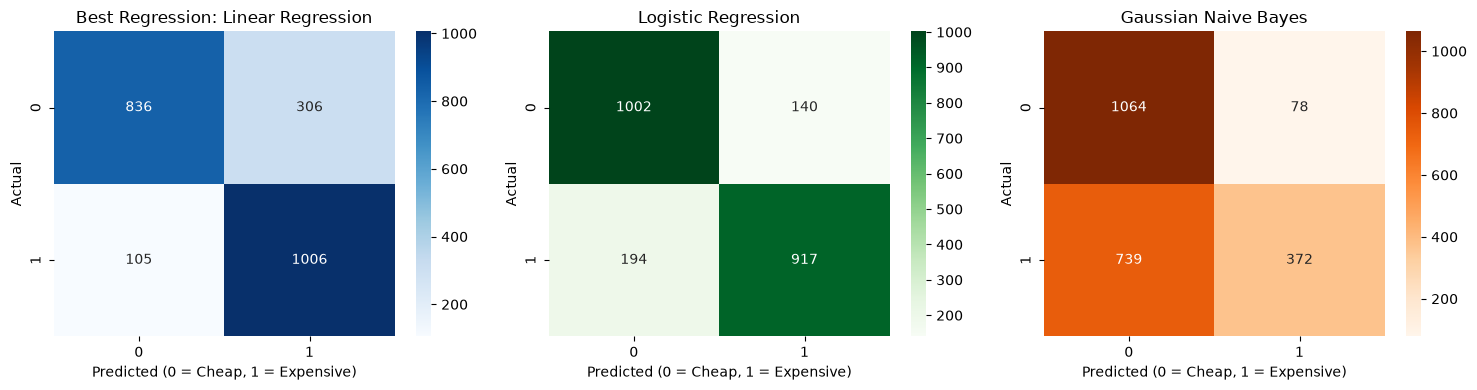

In [211]:
# ===== STEP 16: Cheap vs Expensive pe sabko compare karo, confusion matrix graph ke saath =====
cmp = pd.DataFrame({  # comparison table banao (test data)
    "Model": ["Best Regression: " + best, "Logistic Regression", "Gaussian Naive Bayes"],  # model ke naam
    "Accuracy": [accuracy_score(a_te, b_te), accuracy_score(a_te, lg_te), accuracy_score(a_te, gn_te)],  # kitni predictions sahi thi
    "Precision": [precision_score(a_te, b_te), precision_score(a_te, lg_te), precision_score(a_te, gn_te)],  # jitno ko mehnga bola unme se kitne sach me mehnge the
    "Recall": [recall_score(a_te, b_te), recall_score(a_te, lg_te), recall_score(a_te, gn_te)],  # jo sach me mehnge the unme se kitne pakde
    "F1": [f1_score(a_te, b_te), f1_score(a_te, lg_te), f1_score(a_te, gn_te)],  # precision aur recall ka balance
})
print(cmp.round(3))  # table dikhao

best_c = cmp.sort_values("F1", ascending=False).iloc[0]["Model"]  # sabse zyada F1 wala model
print("Best on Cheap vs Expensive:", best_c)  # winner print karo

plt.figure(figsize=(15, 4))  # 3 graph ke liye bada figure
plt.subplot(1, 3, 1)  # pehla graph
sns.heatmap(confusion_matrix(a_te, b_te), annot=True, fmt="d", cmap="Blues")  # best regression model ka matrix
plt.title("Best Regression: " + best)  # title
plt.xlabel("Predicted (0 = Cheap, 1 = Expensive)")  # x label
plt.ylabel("Actual")  # y label
plt.subplot(1, 3, 2)  # doosra graph
sns.heatmap(confusion_matrix(a_te, lg_te), annot=True, fmt="d", cmap="Greens")  # logistic regression ka matrix
plt.title("Logistic Regression")  # title
plt.xlabel("Predicted (0 = Cheap, 1 = Expensive)")  # x label
plt.ylabel("Actual")  # y label
plt.subplot(1, 3, 3)  # teesra graph
sns.heatmap(confusion_matrix(a_te, gn_te), annot=True, fmt="d", cmap="Oranges")  # naive bayes ka matrix
plt.title("Gaussian Naive Bayes")  # title
plt.xlabel("Predicted (0 = Cheap, 1 = Expensive)")  # x label
plt.ylabel("Actual")  # y label
plt.tight_layout()  # text overlap na ho
plt.show()  # teeno graph dikhao

Conclusion

## Final Conclusion
- **Goal:** Bengaluru ke gharon ki price (lakhs me) predict karna, aur gharon ko Cheap ya Expensive me classify karna.
- **Pipeline:** Load -> Clean -> Feature Engineering -> Outliers Hatao -> EDA -> Encoding -> Split -> Scale -> Models Train -> Evaluate -> Compare.
- **Part A (Regression, price lakhs me):**
  - Models: Linear Regression, KNN, Decision Tree, Random Forest.
  - Metrics: R2, MAE, MSE, RMSE.
  - Best: Linear Regression (Test R2 lagbhag 0.74, RMSE lagbhag 57 lakhs). Iska Train aur Test R2 lagbhag barabar hai, matlab overfitting nahi hai.
  - Random Forest ka MAE sabse kam hai, par uska train R2 (lagbhag 0.95) test R2 se bahut zyada hai, matlab wo overfit karta hai. KNN aur Decision Tree sabse kamzor rahe.
- **Part B (Classification, median price se Cheap vs Expensive):**
  - Models: Logistic Regression aur Gaussian Naive Bayes, best regression model ke saath compare kiye.
  - Metrics: TP, TN, FP, FN, Confusion Matrix, Accuracy, Precision, Recall, F1.
  - Best: Logistic Regression (Accuracy lagbhag 0.85, F1 lagbhag 0.85).
  - Linear Regression ka recall zyada hai (lagbhag 0.90) par false positives bhi zyada hain, isliye Logistic Regression zyada balanced hai.
  - Gaussian Naive Bayes sabse kamzor hai (Recall lagbhag 0.34). Wo bell-curve jaise columns maanta hai, par humare zyada tar columns 0/1 wale location columns hain, isliye wo bahut mehnge ghar miss karta hai (FN zyada).
- **Top features:** total_sqft sabse zyada, fir bath, bhk aur area_type.
- **Aage kya kar sakte hain:** price ka log transform, GridSearchCV se tuning, location-based price features, XGBoost try karna.